# 05 — Filtrage par contenu (TF-IDF)

**Objectif** : recommander des films dont le contenu ressemble à ceux qu'un utilisateur a aimés,
sans utiliser les notes des autres utilisateurs.

Ce notebook charge le modèle entraîné par `python scripts/train_content.py`.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from recsys.analysis import model_report, plots
from recsys.config import load_config

%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 90)

config = load_config()
processed = config.paths.processed_dir
movies = pd.read_parquet(processed / "movies.parquet")
tags = pd.read_parquet(processed / "tags.parquet")


def show(fig):
    display(fig)
    plt.close(fig)

from recsys.experiments import collaborative, content
from recsys.experiments.runner import build_folds, load_ratings
from recsys.models.collaborative import ItemKNN
from recsys.models.content_based import ContentBasedRecommender

artifacts = config.paths.artifacts_dir
tfidf = ContentBasedRecommender.load(artifacts / content.ARTIFACT_DIR / "tfidf.pkl")
matrix = tfidf.matrix
titles = movies.set_index("movieId").loc[matrix.item_ids, "title"].to_numpy()
popularity = np.diff(matrix.ratings.tocsc().indptr)
print("Configuration retenue sur la validation :", tfidf.params)


def find(part):
    matches = [i for i, t in enumerate(titles) if part.lower() in t.lower()]
    return max(matches, key=lambda i: popularity[i])

Configuration retenue sur la validation : {'genre_weight': 0.2, 'tag_weight': 1.0, 'title_weight': 0.3, 'aggregation': 'knn', 'k': 50}


## 1. Films similaires par le contenu

In [2]:
def similar(part, n=8):
    idx = find(part)
    items, sims = tfidf.similar_items(idx, n)
    print("Film de référence :", titles[idx])
    return pd.DataFrame({
        "film": titles[items], "cosinus": sims,
        "termes communs": [", ".join(t.split(":")[1] for t, _ in tfidf.shared_terms(idx, i, 4))
                           for i in items],
    })


similar("Matrix, The")

Film de référence : Matrix, The (1999)


,film,cosinus,termes communs
0,"Matrix Reloaded, The (2003)",0.5732,"matrix, virtual reality, cyberpunk, keanu reeves"
1,"Matrix Revolutions, The (2003)",0.5720,"matrix, virtual reality, cyberpunk, keanu reeves"
2,Tron (1982),0.3257,"virtual reality, cyberpunk, computers, hackers"
3,Johnny Mnemonic (1995),0.3128,"cyberpunk, keanu reeves, hackers, dystopia"
4,Tron: Legacy (2010),0.3122,"virtual reality, artificial intelligence, cyberpunk, computers"
5,Dark City (1998),0.3029,"post apocalyptic, dystopia, alternate reality, thought-provoking"
6,Blade Runner (1982),0.3027,"cyberpunk, artificial intelligence, dystopia, philosophical"
7,Sleep Dealer (2008),0.2626,"dystopia, virtual reality, computers, alternate reality"


In [3]:
similar("Toy Story (1995)")

Film de référence : Toy Story (1995)


,film,cosinus,termes communs
0,Toy Story 2 (1999),0.6893,"pixar, toy, tom hanks, computer animation"
1,Toy Story 3 (2010),0.5154,"pixar, toy, tom hanks, toys"
2,Toy Story That Time Forgot (2014),0.4343,"pixar, toys, computer animation, animation"
3,Ice Age (2002),0.4198,"pixar, animation, animated, disney"
4,"Monsters, Inc. (2001)",0.4121,"pixar, animation, disney, animated"
5,"Bug's Life, A (1998)",0.3903,"pixar, animation, disney, animated"
6,Finding Nemo (2003),0.3880,"pixar, animation, disney, children"
7,"Incredibles, The (2004)",0.3793,"pixar, animation, disney, family"


In [4]:
similar("Amelie")

Film de référence : Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)


,film,cosinus,termes communs
0,Tuvalu (1999),0.2826,"beautifully filmed, stylized, whimsical, quirky"
1,Delicatessen (1991),0.2528,"jean-pierre jeunet, quirky, surreal, french"
2,Priceless (Hors de prix) (2006),0.2499,"audrey tautou, french, Romance, quirky"
3,Playing It Cool (2014),0.2336,"whimsical, romance, comedy, Romance"
4,Eternal Sunshine of the Spotless Mind (2004),0.2317,"imagination, surreal, quirky, Romance"
5,Big Fish (2003),0.2296,"imagination, surreal, quirky, stylized"
6,"Happenstance (Battement d'ailes du papillon, Le) (2001)",0.2247,"audrey tautou, french, audrey tatou, cute"
7,Micmacs (Micmacs à tire-larigot) (2009),0.2219,"jean-pierre jeunet, quirky, visually appealing, french"


Chaque rapprochement est explicable terme à terme : c'est le principal atout du TF-IDF.

## 2. Recommandations pour un utilisateur

Même utilisateur que dans le notebook 04, pour comparer avec le filtrage collaboratif.

In [5]:
fold = build_folds(load_ratings(config), config)["test"]
assert np.array_equal(fold.matrix.item_ids, matrix.item_ids)
history_size = np.diff(matrix.ratings.indptr)
relevant = fold.relevant.groupby("user_idx")["item_idx"].apply(set)
user = [u for u in fold.eval_users if 60 <= history_size[u] <= 150 and len(relevant[u]) >= 8][0]
print(f"Utilisateur {matrix.user_ids[user]} : {history_size[user]} notes avant la coupure")


def top10(model, label):
    items, scores = model.recommend(np.array([user]), k=10)
    rows = []
    for rank, (item, score) in enumerate(zip(items[0], scores[0]), start=1):
        because, _ = model.explain(user, item, n=2)
        rows.append({"modèle": label, "rang": rank, "film": titles[item], "score": score,
                     "aimé ensuite": "oui" if item in relevant[user] else "",
                     "parce que vous avez aimé": " ; ".join(titles[because])})
    return pd.DataFrame(rows)


top10(tfidf, "TF-IDF")

Utilisateur 294 : 117 notes avant la coupure


,modèle,rang,film,score,aimé ensuite,parce que vous avez aimé
0,TF-IDF,1,"Silence of the Lambs, The (1991)",1.8904,,"Shining, The (1980) ; One Flew Over the Cuckoo's Nest (1975)"
1,TF-IDF,2,Eternal Sunshine of the Spotless Mind (2004),1.7907,,Donnie Darko (2001) ; Being John Malkovich (1999)
2,TF-IDF,3,The Machinist (2004),1.6387,,Fight Club (1999) ; American Psycho (2000)
3,TF-IDF,4,Brazil (1985),1.5993,,Donnie Darko (2001) ; Being John Malkovich (1999)
4,TF-IDF,5,Pi (1998),1.5854,,"Donnie Darko (2001) ; Tenant, The (Locataire, Le) (1976)"
5,TF-IDF,6,Requiem for a Dream (2000),1.5504,,One Flew Over the Cuckoo's Nest (1975) ; Trainspotting (1996)
6,TF-IDF,7,Apocalypse Now (1979),1.4885,,"Full Metal Jacket (1987) ; Godfather, The (1972)"
7,TF-IDF,8,Scarface (1983),1.4795,,"Godfather, The (1972) ; Godfather: Part II, The (1974)"
8,TF-IDF,9,Inception (2010),1.4650,,Donnie Darko (2001) ; Memento (2000)
9,TF-IDF,10,City of God (Cidade de Deus) (2002),1.3920,oui,Goodfellas (1990) ; Fight Club (1999)


In [6]:
item_knn = ItemKNN.load(artifacts / collaborative.ARTIFACT_DIR / "item_knn.pkl")
top10(item_knn, "Item-kNN (collaboratif)")

,modèle,rang,film,score,aimé ensuite,parce que vous avez aimé
0,Item-kNN (collaboratif),1,Apocalypse Now (1979),0.8099,,"Taxi Driver (1976) ; Shining, The (1980)"
1,Item-kNN (collaboratif),2,2001: A Space Odyssey (1968),0.7974,,"Eyes Wide Shut (1999) ; Shining, The (1980)"
2,Item-kNN (collaboratif),3,Rosemary's Baby (1968),0.5660,oui,"Shining, The (1980) ; Eyes Wide Shut (1999)"
3,Item-kNN (collaboratif),4,Psycho (1960),0.5323,,"Shining, The (1980) ; Taxi Driver (1976)"
4,Item-kNN (collaboratif),5,"Exorcist, The (1973)",0.5288,oui,"Shining, The (1980) ; Carrie (1976)"
5,Item-kNN (collaboratif),6,Blade Runner (1982),0.4543,,"Shining, The (1980) ; Alien (1979)"
6,Item-kNN (collaboratif),7,Boogie Nights (1997),0.4221,,Eyes Wide Shut (1999) ; Taxi Driver (1976)
7,Item-kNN (collaboratif),8,Blue Velvet (1986),0.3942,,Taxi Driver (1976) ; Eyes Wide Shut (1999)
8,Item-kNN (collaboratif),9,"Deer Hunter, The (1978)",0.3883,,"Taxi Driver (1976) ; Shining, The (1980)"
9,Item-kNN (collaboratif),10,Deliverance (1972),0.3841,,"Taxi Driver (1976) ; Graduate, The (1967)"


In [7]:
content_top = tfidf.recommend(np.array([user]), k=10)[0][0]
collab_top = item_knn.recommend(np.array([user]), k=10)[0][0]
pd.DataFrame({
    "modèle": ["TF-IDF", "Item-kNN"],
    "popularité médiane du top-10 (notes d'entraînement)": [
        np.median(popularity[content_top]), np.median(popularity[collab_top])],
    "films en commun": [len(set(content_top) & set(collab_top))] * 2,
})

,modèle,popularité médiane du top-10 (notes d'entraînement),films en commun
0,TF-IDF,"18,332.0000",1
1,Item-kNN,"13,518.5000",1


## 3. Quel champ compte ? (validation)

In [8]:
results = model_report.load_results(config.paths.reports_dir, content.RESULTS_FILE)
validation = model_report.results_frame(results["validation"])
validation[validation["model"] == "tfidf"][
    ["params", "ndcg@10", "recall@10", "coverage@10", "mean_popularity@10"]
].reset_index(drop=True)

,params,ndcg@10,recall@10,coverage@10,mean_popularity@10
0,"genre_weight=1.0, tag_weight=0.0, title_weight=0.0, aggregation=knn, k=50",0.0168,0.0060,0.3507,"2,501.3872"
1,"genre_weight=1.0, tag_weight=1.0, title_weight=0.0, aggregation=centroid, k=50",0.0026,0.0014,0.0818,386.7658
2,"genre_weight=1.0, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.0571,0.0219,0.2011,"6,201.6814"
3,"genre_weight=0.5, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.0839,0.0353,0.1918,"8,576.3187"
4,"genre_weight=0.5, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",0.0895,0.0375,0.1853,"9,286.2499"
5,"genre_weight=0.2, tag_weight=1.0, title_weight=0.3, aggregation=knn, k=50",0.1028,0.0446,0.1990,"12,136.0918"
6,"genre_weight=0.0, tag_weight=1.0, title_weight=0.0, aggregation=knn, k=50",0.1011,0.0446,0.2008,"12,396.9566"


## 4. Résultat sur le test, face au collaboratif

,precision@10,recall@10,f1@10,map@10,ndcg@10,coverage@10
modèle,,,,,,
Popularité,0.0654,0.0319,0.0310,0.0406,0.0786,0.0188
Item-kNN,0.0881,0.0414,0.0423,0.0551,0.1029,0.2444
ALS implicite,0.1202,0.0597,0.0595,0.0747,0.1381,0.1258
Contenu TF-IDF,0.0890,0.0529,0.0482,0.0572,0.1113,0.2090


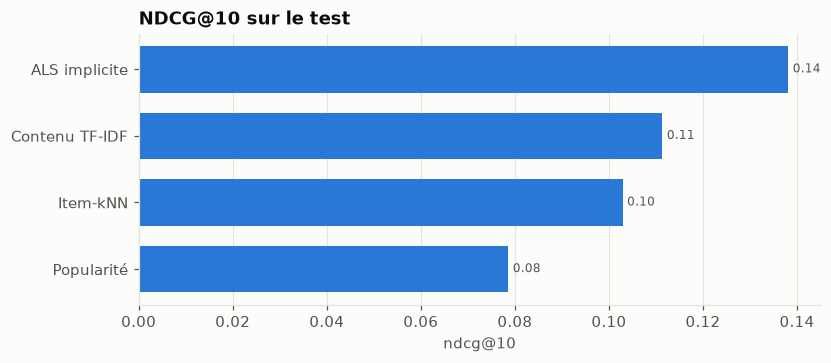

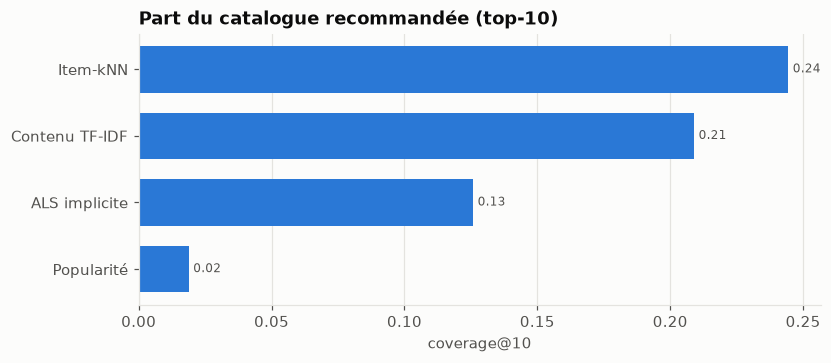

In [9]:
reference = model_report.load_results(config.paths.reports_dir, collaborative.RESULTS_FILE)
rows = [r for r in reference["test"] if r["model"] in ("popularity", "item_knn", "als_implicit")]
rows += [r for r in results["test"] if r["model"] == "tfidf"]
test = model_report.results_frame(rows)
display(model_report.ranking_table(test, 10).set_index("modèle"))
show(model_report.plot_metric(test, "ndcg@10", "NDCG@10 sur le test"))
show(model_report.plot_metric(test, "coverage@10", "Part du catalogue recommandée (top-10)"))

## 5. Avantages et limites

| | |
|---|---|
| **Avantages** | Fonctionne pour un film sans aucune note (cold start film) ; explicable terme à terme ; ne dépend pas des autres utilisateurs ; recommande des films moins populaires |
| **Limites** | Dépend entièrement de la qualité des tags ; ignore la qualité perçue d'un film ; enferme l'utilisateur dans ce qu'il connaît déjà ; correspondance exacte des termes (`sci-fi` et `science fiction` sont deux mots différents) |

La dernière limite est précisément ce que les embeddings du notebook 06 cherchent à lever.